# Sampling analysis
Run all cells from top to bottom. All tables are loaded in the first section.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency
from skbio.diversity import alpha

In [2]:
# software versions (reported in Methods)
import sys, importlib
print('Python', sys.version.split()[0])
for name in ['scipy', 'pandas', 'numpy', 'matplotlib', 'seaborn', 'skbio']:
    print(name, importlib.import_module(name).__version__)

Python 3.13.9
scipy 1.17.1
pandas 3.0.3
numpy 2.4.6
matplotlib 3.10.9
seaborn 0.13.2
skbio 0.7.3


# Load data

In [2]:
samples = pd.read_excel('Tables/Supplemental Table 1.xlsx')        # environmental samples
tardigrades = pd.read_excel('Tables/Supplemental Table 2.xlsx')    # tardigrades in each sample
sequence_df = pd.read_excel('Tables/Supplemental Table 3.xlsx')    # 18S sequences and OTUs
otu_order = pd.read_excel('Tables/Table 3.xlsx')['OTU'].values     # OTUs, in Table 3 order

moss_samples = samples[samples['Substrate']=='moss']['UniqueID'].unique()
lichen_samples = samples[samples['Substrate']=='lichen']['UniqueID'].unique()
locations = dict(zip(samples['UniqueID'], samples['Location']))

# sequenced individuals (no consensus rows) in the OTUs of Table 3
sequenced = sequence_df[(sequence_df['SeqID'] != 'consensus') & sequence_df['OTU'].isin(otu_order)]
id_to_otu = dict(zip(sequenced['SeqID'], sequenced['OTU']))

# otu --> list of environmental sample IDs (tardigrade ID minus the '-tNN' suffix)
samples_in_otu = {otu: list(dict.fromkeys(x[:-4] for x in sequenced.loc[sequenced['OTU'] == otu, 'SeqID']))
                  for otu in otu_order}

print('samples:', len(samples), ' moss:', len(moss_samples), ' lichen:', len(lichen_samples))
print('Total Tardigrades: ', len(tardigrades))
print('Sequenced tardigrades: ', len(sequenced))

samples: 264  moss: 207  lichen: 53
Total Tardigrades:  761
Sequenced tardigrades:  428


# Table 1 and Supplemental Figure 1


all samples
Number of samples :  264
Number of samples with tardigrades :  199
Number of samples without tardigrades :  65
Percentage of samples with tardigrades :  75.0
Mean number tardigrades per sample :  2.88
Number of samples with >= 10 : 18

moss samples
Number of samples :  207
Number of samples with tardigrades :  153
Number of samples without tardigrades :  54
Percentage of samples with tardigrades :  74.0
Mean number tardigrades per sample :  3.0
Number of samples with >= 10 : 16

lichen samples
Number of samples :  53
Number of samples with tardigrades :  44
Number of samples without tardigrades :  9
Percentage of samples with tardigrades :  83.0
Mean number tardigrades per sample :  2.51
Number of samples with >= 10 : 2


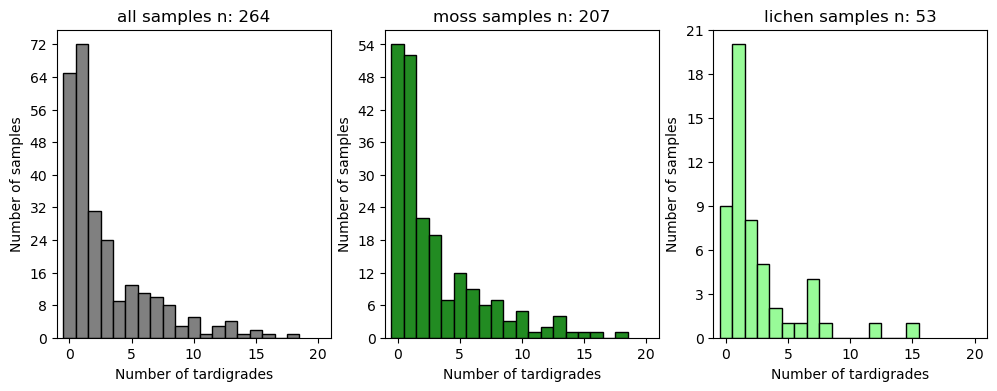

,Data,all samples,moss samples,lichen samples
0,Number of samples,264.00,207.0,53.00
1,Number of samples with tardigrades,199.00,153.0,44.00
2,Number of samples without tardigrades,65.00,54.0,9.00
3,Percentage of samples with tardigrades,75.00,74.0,83.00
4,Mean number tardigrades per sample,2.88,3.0,2.51


In [3]:
year_threshold = 2020 # when to start keeping track
count_threshold = 10  # count samples with at least this many tardigrades

tardigrades_per_sample = tardigrades.groupby('Sample ID').size()

id_types = ['all samples', 'moss samples', 'lichen samples']
colors = ['gray', 'forestgreen', 'palegreen']
id_groups = [sorted(samples['UniqueID'].unique()), moss_samples, lichen_samples]

sampletype_data = {'Data': ['Number of samples',
                            'Number of samples with tardigrades',
                            'Number of samples without tardigrades',
                            'Percentage of samples with tardigrades',
                            'Mean number tardigrades per sample']}

f, axes = plt.subplots(1,3,figsize=(12,4))
for i, ids in enumerate(id_groups):
    ids = [x for x in ids if int(x[:4]) >= year_threshold]
    numbers_in_samples = np.array([tardigrades_per_sample.get(x, 0) for x in ids])

    number_of_samples = len(numbers_in_samples)
    num_with_tardigrades = int(np.sum(numbers_in_samples > 0))
    data_this_sample = [number_of_samples,
                        num_with_tardigrades,
                        number_of_samples - num_with_tardigrades,
                        np.round(100 * num_with_tardigrades / number_of_samples),
                        np.round(np.mean(numbers_in_samples), 2)]
    sampletype_data[id_types[i]] = data_this_sample

    print()
    print(id_types[i])
    for lab, val in zip(sampletype_data['Data'], data_this_sample):
        print(lab, ': ', val)
    print('Number of samples with >=', count_threshold, ':', np.sum(numbers_in_samples >= count_threshold))

    # histogram, with a bar for every integer
    bins = np.arange(numbers_in_samples.min(), numbers_in_samples.max() + 2) - 0.5
    axes[i].hist(numbers_in_samples, bins=bins, edgecolor='black', align='mid', facecolor=colors[i])
    axes[i].set_title(id_types[i] + ' n: ' + str(number_of_samples))
    axes[i].set_xlabel('Number of tardigrades')
    axes[i].set_ylabel('Number of samples')
    axes[i].set_xlim([-1, 21])
    axes[i].yaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.savefig('Supplemental Figure 1.svg', bbox_inches='tight')
plt.show()

mosslichen_df = pd.DataFrame(sampletype_data)
mosslichen_df.to_excel('Table 1 - new.xlsx', index=False)
mosslichen_df

In [4]:
# Fisher's exact test: are tardigrades found more often in moss or in lichen samples?
observed = np.array([sampletype_data['moss samples'][1:3],
                     sampletype_data['lichen samples'][1:3]])
print(observed)
odds_ratio, p_value = stats.fisher_exact(observed)
print(f"Odds ratio: {odds_ratio:.3f}")
print(f"P-value: {p_value:.3f}")

[[153  54]
 [ 44   9]]
Odds ratio: 0.580
P-value: 0.209


# Table 4: OTUs and sampling

In [5]:
num_moss = len(moss_samples)
num_lichen = len(lichen_samples)

def otu_sample_table(keep_samples=None):
    # For each OTU: number of samples, locations, and moss and lichen samples.
    # If keep_samples is given, only those samples are counted.
    rows = []
    for otu in otu_order:
        samples_for_this_otu = samples_in_otu[otu]
        if keep_samples is not None:
            samples_for_this_otu = [x for x in samples_for_this_otu if x in keep_samples]
        num_locations = len(np.unique([locations[x] for x in samples_for_this_otu]))
        moss_with_otu = len([x for x in moss_samples if x in samples_for_this_otu])
        lichen_with_otu = len([x for x in lichen_samples if x in samples_for_this_otu])
        rows.append([otu, len(samples_for_this_otu), num_locations,
                     moss_with_otu, np.round(moss_with_otu / num_moss * 100, 1),
                     lichen_with_otu, np.round(lichen_with_otu / num_lichen * 100, 1)])
    return pd.DataFrame(rows, columns=['OTU', '# samples', '# locations', 'moss samples',
                                       '% of moss samples', 'lichen samples', '% of lichen samples'])

otu_sample_df = otu_sample_table()
otu_sample_df.to_excel('Table 4 - new.xlsx', index=False)
otu_sample_df.head(31)

,OTU,# samples,# locations,moss samples,% of moss samples,lichen samples,% of lichen samples
0,Pseudechiniscus sp. a,8,6,6,2.9,2,3.8
1,Viridiscus sp. a,3,1,3,1.4,0,0.0
2,Viridiscus sp. a3,2,1,2,1.0,0,0.0
3,Echiniscus sp. b,7,5,5,2.4,2,3.8
4,Milnesium sp. a,20,11,14,6.8,6,11.3
5,Ramazzottius sp. a,5,2,5,2.4,0,0.0
6,Ramazzottius sp. b,6,3,6,2.9,0,0.0
7,Ramazzottius sp. b1,25,6,13,6.3,12,22.6
8,Ursulinius sp. a,1,1,1,0.5,0,0.0
9,Isohypsibius sp. a,2,2,2,1.0,0,0.0


# Community composition, moss vs. lichen
Group OTUs by genus. Omit genera with low (<5) counts in moss or lichen. Chi-squared test.

In [6]:
df_for_stats = otu_sample_df.copy()
# genus = first word of the OTU name (e.g., 'Macrobiotus sp. f1' -> 'Macrobiotus')
df_for_stats['Genus'] = df_for_stats['OTU'].str.split().str[0]

genus_counts = (df_for_stats
                .groupby('Genus', sort=True)[['moss samples', 'lichen samples']]
                .sum())

min_count = 5
large = genus_counts[(genus_counts['moss samples'] >= min_count) &
                     (genus_counts['lichen samples'] >= min_count)]

print(large)
chi2, p_value, dof, expected = chi2_contingency(large.T.values)
print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"p-value: {p_value:.4f}")
print(f"Degrees of Freedom: {dof}")

              moss samples  lichen samples
Genus                                     
Macrobiotus             51              12
Milnesium               14               6
Minibiotus              33               8
Ramazzottius            24              12
Chi-Square Statistic: 3.4330
p-value: 0.3296
Degrees of Freedom: 3


# Sampling saturation
OTU accumulation curve for samples within the Finger Lakes region.

In [7]:
# sequenced tardigrades with their OTUs, sorted by sample ID (= sample date)
sequenced_tardigrade_df = tardigrades[tardigrades['UniqID'].isin(sequenced['SeqID'])].copy()
sequenced_tardigrade_df['OTU'] = sequenced_tardigrade_df['UniqID'].map(id_to_otu)
sequenced_tardigrade_df = sequenced_tardigrade_df.sort_values(by='Sample ID', kind='stable')

# remove samples from outside the Finger Lakes region (sample ID prefixes)
outside_region = {'20260527': 'Georgia',
                  '20260528': 'Virginia',
                  '20260318': 'Puerto Rico',
                  '20260524-s01': 'Cranberry Lake'}

print('Starting with ...')
print(len(sequenced_tardigrade_df), 'tardigrades')
print(sequenced_tardigrade_df['Sample ID'].nunique(), 'samples')
print()
filtered_df = sequenced_tardigrade_df
for prefix, place in outside_region.items():
    filtered_df = filtered_df[~filtered_df['Sample ID'].str.startswith(prefix, na=False)]
    print(len(filtered_df), 'tardigrades with', place, 'removed')
print()
print(filtered_df['Sample ID'].nunique(), 'samples')
print(filtered_df['OTU'].nunique(), 'OTUs')

Starting with ...
428 tardigrades
158 samples

417 tardigrades with Georgia removed
402 tardigrades with Virginia removed
401 tardigrades with Puerto Rico removed
394 tardigrades with Cranberry Lake removed

149 samples
30 OTUs


sample          OTU          	#samps	#otus
20200511-s01	Macrobiotus sp. f	1	1
20200524-s01	Isohypsibius sp. a2	2	2
20200524-s01	Minibiotus sp. a	2	3
20200524-s02	Milnesium sp. a	3	4
20200617-s06	Macrobiotus sp. f1	6	5
20200629-s03	Hypsibius sp. d	8	6
20200629-s04	Diphascon sp. a	9	7
20200629-s05	Adropion sp. a	10	8
20200703-s02	Mesobiotus sp. a	13	9
20210901-s01	Ramazzottius sp. a	14	10
20210901-s01	Viridiscus sp. a3	14	11
20210901-s03	Ramazzottius sp. b1	16	12
20240926-s01	Paramacrobiotus sp. a	18	13
20240926-s24	Macrobiotus sp. a	23	14
20241002-s01	Paramacrobiotus sp. b	24	15
20241002-s04	Hypsibius sp. b	27	16
20241002-s10	Macrobiotus sp. b	30	17
20241009-s05	Viridiscus sp. a	36	18
20241009-s08	Macrobiotus sp. e	37	19
20241021-s02	Ramazzottius sp. b	43	20
20260516-s01	Pseudechiniscus sp. a	60	21
20260516-s05	Isohypsibius sp. a	61	22
20260516-s07	Echiniscus sp. b	63	23
20260517-s01	Hypsibius sp. c	64	24
20260521-s02	Mesobiotus sp. a1	65	25
20260531-s05	Hypsibius sp. a	71	26
20260604-s

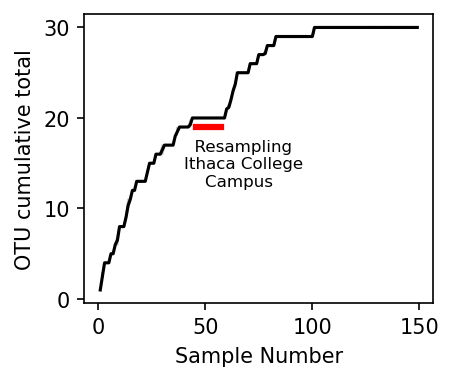

In [8]:
# count samples and OTUs as each new sample is added
# species are printed out in the order found
sample_count = 0
current_sample = ''
counted_otus = []
sample_axis = []
otu_axis = []

print('sample          OTU          \t#samps\t#otus')
for sample_id, otu in zip(filtered_df['Sample ID'].values, filtered_df['OTU'].values):
    if sample_id != current_sample: # a new sample
        current_sample = sample_id
        sample_count += 1
    if otu not in counted_otus and 'unknown' not in otu:
        counted_otus.append(otu)
        print('\t'.join([sample_id, otu, str(sample_count), str(len(counted_otus))]))
    sample_axis.append(sample_count)
    otu_axis.append(len(counted_otus))

f, ax = plt.subplots(1,1,figsize=(3,2.5), dpi=150)
sns.lineplot(x=sample_axis, y=otu_axis, color='k', ax=ax)
plt.text(40, 12.5, '  Resampling\nIthaca College\n    Campus', fontsize=8)
plt.plot([45.5, 57.5], [19, 19], '-r', linewidth=3)
plt.xlabel('Sample Number', fontsize=10)
plt.ylabel('OTU cumulative total', fontsize=10)
ax.tick_params(axis="both", labelsize=10)
# plt.savefig('figx_species_accumulation.png', bbox_inches='tight', transparent=True)
plt.show()

The plot above shows the *new* samples in the Finger Lakes region. Resampling efforts within already-sampled regions are not shown.

In [9]:
# OTU richness estimates, using the number of Finger Lakes samples containing each OTU
good_samples = set(filtered_df['Sample ID'])
otu_goodsample_df = otu_sample_table(keep_samples=good_samples)
otu_goodsamples_above_zero_df = otu_goodsample_df[otu_goodsample_df['# samples'] > 0]
print(len(otu_goodsamples_above_zero_df), 'OTUs in Finger Lakes samples')

sample_counts = otu_goodsamples_above_zero_df['# samples'].values
print(f"Chao1: {alpha.chao1(sample_counts):.2f}")
print(f"ACE: {alpha.ace(sample_counts):.2f}")

30 OTUs in Finger Lakes samples
Chao1: 30.60
ACE: 31.02
